In [85]:
import kagglehub
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
import string
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import re
from wordcloud import STOPWORDS

In [86]:
#variables i will need
lem=WordNetLemmatizer()
port=PorterStemmer()

In [87]:

# Download latest version
df=pd.read_csv("email_spam_indo.csv",usecols=['Kategori','Pesan'])
print(df.shape)
df.head(10)


(2636, 2)


,Kategori,Pesan
0,spam,Secara alami tak tertahankan identitas perusah...
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak..."
5,spam,"Nnews yang hebat halo, selamat datang di medzo..."
6,spam,Berikut ini adalah permainan panas di Investme...
7,spam,Simpan uang Anda beli untuk mendapatkan barang...
8,spam,Tidak Terkirim: Bisnis Berbasis Rumah Untuk Or...
9,spam,Simpan uang Anda beli untuk mendapatkan barang...


In [88]:
#check how many of each category, plot pie chart
print(df.describe())

       Kategori                                              Pesan
count      2636                                               2636
unique        2                                               2620
top        spam  Manoj Gupta - Jadwal Wawancara Terlampir Anda ...
freq       1368                                                  2


In [89]:
print(df.dropna())

     Kategori                                              Pesan
0        spam  Secara alami tak tertahankan identitas perusah...
1        spam  Fanny Gunslinger Perdagangan Saham adalah Merr...
2        spam  Rumah -rumah baru yang luar biasa menjadi muda...
3        spam  4 Permintaan Khusus Pencetakan Warna Informasi...
4        spam  Jangan punya uang, dapatkan CD perangkat lunak...
...       ...                                                ...
2631      ham  Pengingat halo semuanya: Vince telah meminta s...
2632      ham  Re: Argentina Power & Gas Market Modeling Oke ...
2633      ham  Re: Program Enron / Stanford Stinson, hebat! S...
2634      ham  Persetujuan untuk peninjau Roberts JR, Michael...
2635      ham  Re: Seminar Bollerslev sangat bagus. Terima ka...

[2636 rows x 2 columns]


finding: no missing values, no duplicate values

In [90]:
val_counts=df['Kategori'].value_counts()
val_counts


Kategori
spam    1368
ham     1268
Name: count, dtype: int64

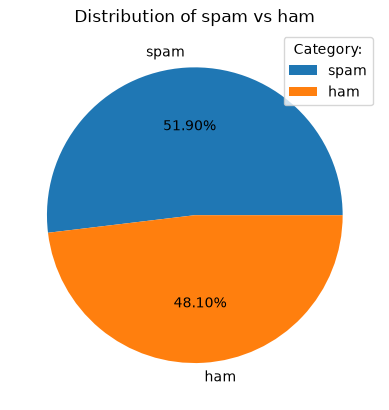

In [91]:
#plot pie chart of distribution
plt.pie(
    x=val_counts,
    labels=val_counts.index,
    autopct='%.2f%%'
    )
plt.legend(title = "Category:")
plt.title('Distribution of spam vs ham')
plt.show()

findings: more spam than ham in this dataset

In [92]:
#examine emails length, vocab size
email_length=df['Pesan'].str.len()
print('Email Length Summary')
email_length.describe()

Email Length Summary


count     2636.000000
mean      1481.520106
std       2215.573869
min          3.000000
25%        446.000000
50%        860.000000
75%       1626.000000
max      33531.000000
Name: Pesan, dtype: float64

In [93]:
#by category
spam_cat=df[df['Kategori']=='spam']
ham_cat=df[df['Kategori']=='ham']

spam_length=spam_cat['Pesan'].str.len()
ham_length=ham_cat['Pesan'].str.len()
spam_length.describe()

count     1368.000000
mean      1351.805556
std       2343.474611
min          6.000000
25%        395.000000
50%        707.000000
75%       1297.500000
max      29757.000000
Name: Pesan, dtype: float64

In [94]:
ham_length.describe()

count     1268.000000
mean      1621.464511
std       2060.520957
min          3.000000
25%        531.750000
50%       1090.000000
75%       1981.000000
max      33531.000000
Name: Pesan, dtype: float64

In [95]:
#correlation matrix of length on
df_length=df[['Kategori']]
df_length['Kategori']=df_length['Kategori']=='ham'
df_length['Length']=df['Pesan'].str.len()
df_length.head()

,Kategori,Length
0,False,1504
1,False,559
2,False,484
3,False,504
4,False,251


          Kategori    Length
Kategori  1.000000  0.060823
Length    0.060823  1.000000


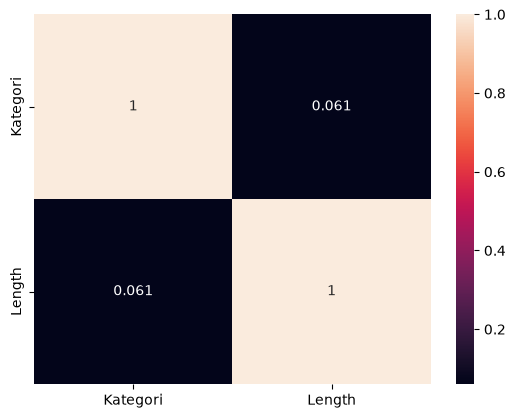

In [96]:
import seaborn as sns
df_length_corr=df_length.corr()
print(df_length_corr)
ax = sns.heatmap(df_length_corr, annot=True)

finding: extremely weak correlation between length and spam

In [97]:
#look at length of comments
df[df['Pesan'].str.len()<20]

,Kategori,Pesan
568,spam,. JIF.
1990,ham,FYI
2262,ham,Elena Chilkina Hai
2566,ham,Badai Elana ini


In [98]:
#see summary of length
#plot histogram of length of pesan

In [99]:
# Get the highest value
highest_value = df['Pesan'].str.len().max()
print("Highest Value:", highest_value)

Highest Value: 33531


In [100]:
highest_value = df['Pesan'].str.len().sort_values(ascending=False)
highest_value.head()


2337    33531
536     29757
2559    28295
151     23068
126     19470
Name: Pesan, dtype: int64

In [101]:
#analyze vocabulary size

def analyzeVocabSize(dataframe):
    text = ' '.join(dataframe['Pesan'].astype(str).tolist())

    text = re.sub(r'[^A-Za-z\s]', '', text)

    text = text.lower()
    # specific_words={'enron','ect','cc','kaminski','vince','j'}
    # banned_words=stopwords.union(specific_words)
    banned_words=stopwords
    text = ' '.join(word for word in text.split() if word not in banned_words)
    set_words = pd.Series(text.split()).value_counts().to_dict()
    print("Vocab list:")
    print(set_words)
    print("Vocab list:")
    print(len(set_words))
    return set_words


In [102]:
ind_stopwords=stopwords.words("indonesian")
stopwords = set(ind_stopwords)

In [103]:
print("Spam analysis")
spam_v=analyzeVocabSize(spam_cat)
print("Ham analysis")
ham_v=analyzeVocabSize(ham_cat)

Spam analysis
Vocab list:
{'perusahaan': 1198, 'com': 990, 'email': 939, 'situs': 937, 'bisnis': 790, 'informasi': 770, 'orang': 755, 'uang': 749, 'web': 710, 'memiliki': 702, 'http': 601, 'e': 578, 'menerima': 563, 'gratis': 557, 'pesan': 545, 'harga': 524, 'klik': 519, 'surat': 486, 'lunak': 483, 'laporan': 463, 'adobe': 462, 'alamat': 449, 'perangkat': 448, 'www': 424, 'a': 417, 'saham': 364, 'program': 357, 'daftar': 355, 'investasi': 355, 'layanan': 354, 'online': 347, 'nama': 346, 'negara': 330, 'pernyataan': 330, 'pelanggan': 326, 'akun': 323, 'produk': 316, 'silakan': 316, 'pasar': 311, 'rumah': 295, 'menghasilkan': 295, 'sistem': 288, 'penawaran': 286, 'biaya': 285, 'cepat': 283, 's': 277, 'internet': 277, 'terbaik': 271, 'mail': 259, 'iklan': 259, 'tersedia': 256, 'dunia': 255, 'membantu': 253, 'kirim': 251, 'logo': 243, 'khusus': 243, 'l': 243, 'salah': 242, 'juta': 242, 'pemasaran': 240, 'keamanan': 237, 'mudah': 234, 'teknologi': 233, 'r': 226, 'x': 225, 'industri': 221, '

In [104]:
#store to spam dict txt and ham dict txt
import json
with open("spam_dict.json", "w") as f:
  json.dump(spam_v,f)
f.close()
with open("ham_dict.json", "w") as f:
  json.dump(ham_v,f)
f.close()


named entites in ham dataset, namely Enron, Vincent "Vince" J. Kaminski, Shirley.

the word 'viagra' never shows up in ham rows while it shows up 173 times in spam
many spelling mistakes in spam_dict

In [105]:
def showCloud(dataframe):
    text = ' '.join(dataframe['Pesan'].astype(str).tolist())

    text = re.sub(r'[^A-Za-z\s]', '', text)

    text = text.lower()
    specific_words={'enron','ect','cc','kaminski','vince','ect','hou','shirley'}
    banned_words=stopwords.union(specific_words)
    text = ' '.join(word for word in text.split() if word not in banned_words)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title("Word Cloud")
    plt.show()

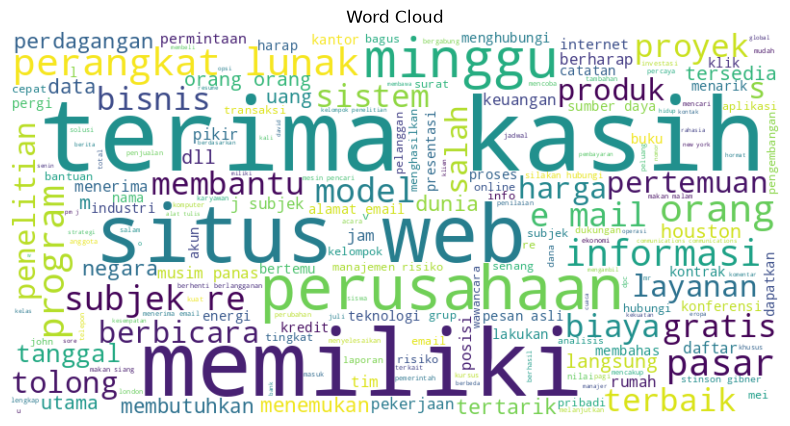

In [106]:
showCloud(df)

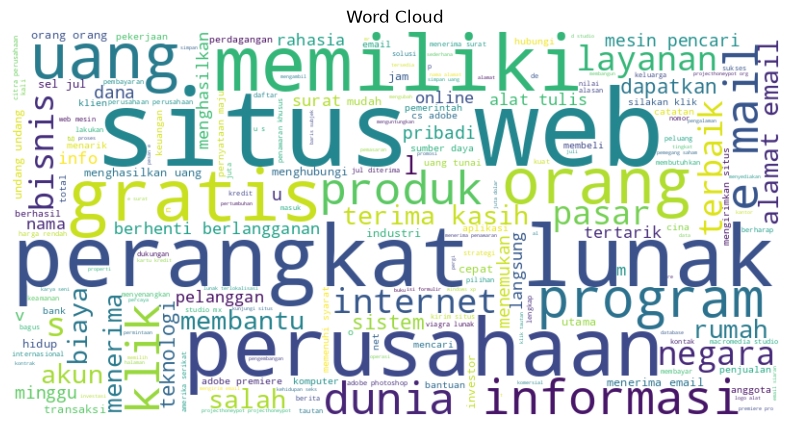

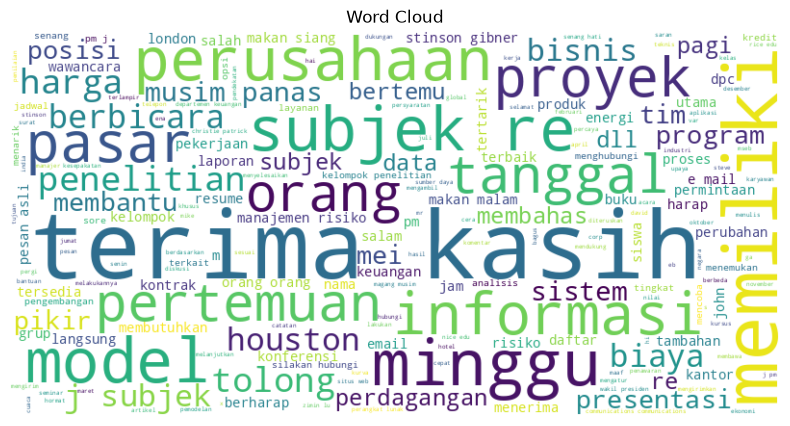

In [107]:
#repeat with spam and nonspam categories
#spam
spam_df = df[df['Kategori']=='spam']
showCloud(spam_df)

ham_df = df[df['Kategori']=='ham']
showCloud(ham_df)

In [108]:
#to do list: remove the name vince j kaminski, enron, shirley crenshaw

In [109]:
#n-gram analysis

In [110]:
#sentiment analysis

In [111]:
#part-of-speech-tagging

In [112]:
#topic modelling with Latent Dirichlet Allocation

Analyze the total number of emails and the distribution of spam versus legitimate emails. This is to adjust our strategy in case there is an imbalance in the dataset. After this we will examine the general length of emails and vocabulary size, check for missing values and remove duplicate emails. Frequency analysis of non-stopword words will be carried out and displayed via WordCloud. Other tasks that will be carried out include n-gram analysis, sentiment analysis, part-of-speech tagging and topic modelling using Latent Dirichlet Allocation. This will give us insight into what spam emails typically talk about vs ham emails, potentially revealing common techniques spam emails use to get users to click on them.
